# Phase 10: Embedding Visualization
We extract the high-dimensional feature embeddings from both the **Baseline CNN** and the **ResNet18 (Transfer Learning)** model. 
We then apply **t-SNE** and **UMAP** dimensionality reduction techniques to project these embeddings into 2D space. By visualizing these clusters, we can empirically compare the representation learning power of a CNN trained from scratch vs. a pre-trained ResNet.

In [1]:
import sys
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.manifold import TSNE
import umap

sys.path.append(str(Path.cwd().parent))

from configs.paths import EUROSAT_DIR, OUTPUTS_DIR
from data.dataset_loader import SatelliteDatasetLoader
from models.baseline_cnn import BaselineCNN
from models.resnet_transfer import ResNet18Transfer

# Device Configuration
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## 1. Load Data
We will extract embeddings for a subset of the dataset (the validation/test set) to keep the t-SNE computation time reasonable.

In [2]:
loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='random')
_, val_loader, _ = loader.get_dataloaders()
classes = loader.classes
num_classes = len(classes)

2026-07-12 21:20:16,279 - INFO - DatasetLoader - Loaded dataset from D:\Main Project\data\datasets\eurosat\EuroSAT containing 27000 images across 10 classes.
2026-07-12 21:20:16,280 - INFO - DatasetLoader - Generating Random split indices...
2026-07-12 21:20:16,500 - INFO - DatasetLoader - Successfully generated DataLoaders. Train size: 18900, Val size: 4050, Test size: 4050


## 2. Load Models & Feature Extractors
We load the trained weights and strip the final classification layers to access the dense feature vectors.

In [3]:
# Load Baseline CNN
baseline_model = BaselineCNN(num_classes=num_classes).to(device)
try:
    baseline_model.load_state_dict(torch.load(OUTPUTS_DIR / 'baseline_cnn_best.pth', map_location=device))
except Exception as e:
    print(f"Could not load Baseline CNN: {e}")
baseline_model.eval()

# Load ResNet18
resnet_model = ResNet18Transfer(num_classes=num_classes).to(device)
try:
    resnet_model.load_state_dict(torch.load(OUTPUTS_DIR / 'resnet18_best.pth', map_location=device))
except Exception as e:
    print(f"Could not load ResNet18: {e}")
resnet_model.eval()

# Feature Extractors using Forward Hooks
baseline_features = []
resnet_features = []
labels_list = []

def baseline_hook(module, input, output):
    baseline_features.append(output.detach().cpu().numpy())

def resnet_hook(module, input, output):
    resnet_features.append(output.detach().cpu().numpy().squeeze())

# Attach hooks just before the final fully connected layers
baseline_model.fc1.register_forward_hook(baseline_hook)
resnet_model.backbone.avgpool.register_forward_hook(resnet_hook)

## 3. Extract Embeddings
We run a single epoch over the validation data to harvest the embeddings.

In [4]:
from tqdm import tqdm

print("Extracting embeddings...")
with torch.no_grad():
    for inputs, labels in tqdm(val_loader):
        inputs = inputs.to(device)
        
        _ = baseline_model(inputs)
        _ = resnet_model(inputs)
        
        labels_list.extend(labels.numpy())

# Concatenate all batches
X_baseline = np.concatenate(baseline_features, axis=0)
X_resnet = np.concatenate(resnet_features, axis=0)
y = np.array(labels_list)

print(f"Baseline Embeddings Shape: {X_baseline.shape}")
print(f"ResNet18 Embeddings Shape: {X_resnet.shape}")

Extracting embeddings...


  0%|          | 0/127 [00:00<?, ?it/s]d:\Main Project\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
100%|██████████| 127/127 [01:57<00:00,  1.08it/s]

Baseline Embeddings Shape: (4050, 512)
ResNet18 Embeddings Shape: (4050, 512)


## 4. Compute t-SNE & UMAP Projections
We project the 512-dimensional vectors down to 2 dimensions.

In [5]:
# Subsample to speed up t-SNE/UMAP if dataset is large (e.g., take 2000 points)
max_samples = min(2000, len(y))
idx = np.random.choice(len(y), max_samples, replace=False)

X_base_sub = X_baseline[idx]
X_res_sub = X_resnet[idx]
y_sub = y[idx]

print("Computing t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_base = tsne.fit_transform(X_base_sub)
tsne_res = tsne.fit_transform(X_res_sub)

print("Computing UMAP...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
umap_base = reducer.fit_transform(X_base_sub)
umap_res = reducer.fit_transform(X_res_sub)

print("Projections complete.")

Computing t-SNE...
Computing UMAP...


d:\Main Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Projections complete.


## 5. Visual Comparison
We plot the projections. A better model will show tighter, well-separated clusters corresponding to the true classes.

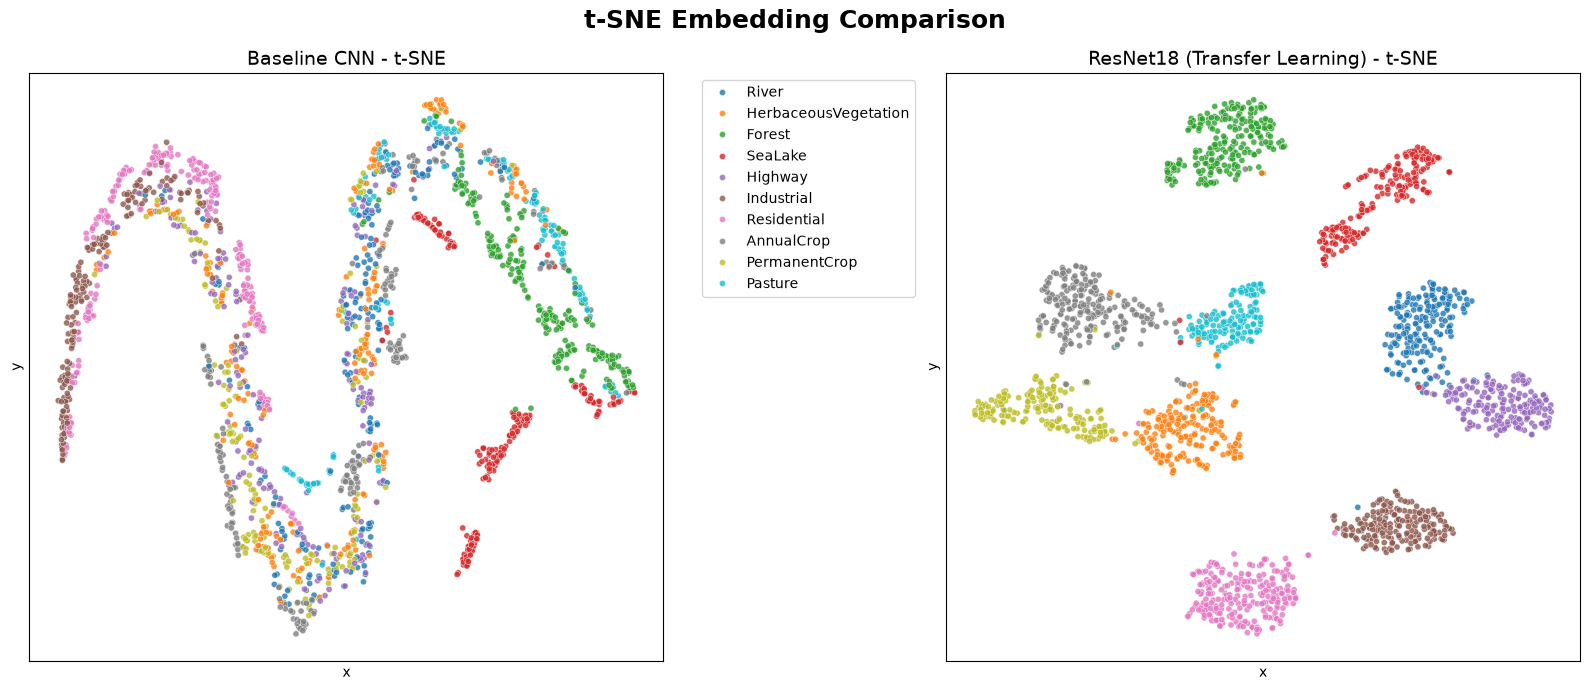

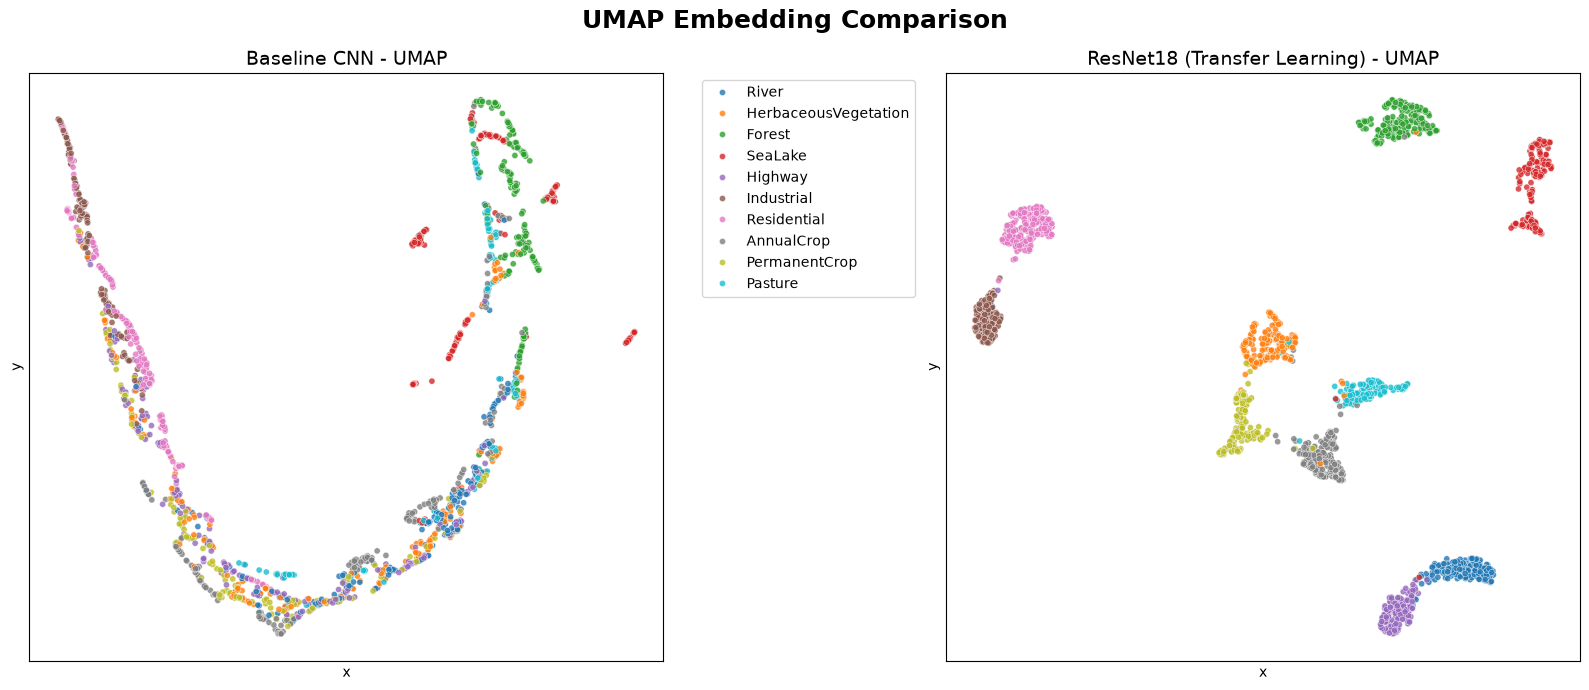

In [6]:
def plot_projections(proj_base, proj_res, title, algorithm_name):
    df_base = pd.DataFrame({'x': proj_base[:, 0], 'y': proj_base[:, 1], 'Class': [classes[lbl] for lbl in y_sub]})
    df_res = pd.DataFrame({'x': proj_res[:, 0], 'y': proj_res[:, 1], 'Class': [classes[lbl] for lbl in y_sub]})
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    sns.scatterplot(data=df_base, x='x', y='y', hue='Class', palette='tab10', s=20, alpha=0.8, ax=axes[0])
    axes[0].set_title(f"Baseline CNN - {algorithm_name}", fontsize=14)
    axes[0].legend(loc='best', bbox_to_anchor=(1.05, 1))
    axes[0].set_xticks([])
    axes[0].set_yticks([])
    
    sns.scatterplot(data=df_res, x='x', y='y', hue='Class', palette='tab10', s=20, alpha=0.8, ax=axes[1], legend=False)
    axes[1].set_title(f"ResNet18 (Transfer Learning) - {algorithm_name}", fontsize=14)
    axes[1].set_xticks([])
    axes[1].set_yticks([])
    
    plt.suptitle(title, fontsize=18, weight='bold')
    plt.tight_layout()
    plt.show()

plot_projections(tsne_base, tsne_res, "t-SNE Embedding Comparison", "t-SNE")
plot_projections(umap_base, umap_res, "UMAP Embedding Comparison", "UMAP")